In [3]:
from pathlib import Path
import json
import os
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.models import (
    resnet50,
    convnext_tiny,
    swin_t,
    efficientnet_b0,
)
from tqdm.auto import tqdm

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", DEVICE)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: NVIDIA GeForce RTX 5060 Laptop GPU


## 1. Reproducibility and project paths

In [4]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

def find_project_root(start=None):
    start = (start or Path.cwd()).resolve()

    for candidate in [start, *start.parents]:
        if (candidate / "pyproject.toml").exists():
            return candidate

    raise FileNotFoundError(
        "Could not find pyproject.toml and therefore the project root."
    )

PROJECT_ROOT = find_project_root()

DATA_DIR = PROJECT_ROOT / "data"
MODEL_DIR = PROJECT_ROOT / "models"
REPORT_DIR = (
    PROJECT_ROOT
    / "reports"
    / "confidence_calibration_final"
)

REPORT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

print("Project root:", PROJECT_ROOT)

Project root: C:\Users\elesh\Academics\UTS\36127InnovationLab\Development\AutoVision_Model_Development


## 2. Classifier configuration

In [19]:
TASKS = {
    "make_model": {
        "enabled": True,
        "architecture": "resnet50",
        "split_path": None,
        "checkpoint_path": None,

        "split_filename_candidates": [
            "make_model_split.csv",
            "make-model_split.csv",
        ],

        "checkpoint_keywords": [
            "make_model",
            "resnet",
        ],
    },

    "body_type": {
        "enabled": True,
        "architecture": "convnext_tiny",
        "split_path": None,
        "checkpoint_path": None,

        "split_filename_candidates": [
            "body_type_split.csv",
            "body-type_split.csv",
        ],

        "checkpoint_keywords": [
            "body_type",
            "convnext",
        ],
    },

    "colour": {
        "enabled": True,
        "architecture": "swin_t",
        "split_path": (
            PROJECT_ROOT
            / "data"
            / "interim"
            / "compcars_colour_controlled_split.csv"
        ),
        "checkpoint_path": None,

        "split_filename_candidates": [
            "colour_split.csv",
            "color_split.csv",
            "surveillance_colour_split.csv",
            "surveillance_color_split.csv",
        ],

        "checkpoint_keywords": [
            "colour",
            "swin",
        ],
    },
}

## 3. Split checkpoint discovery

In [20]:
SEARCH_DIRS_FOR_SPLITS = [
    DATA_DIR / "interim",
    DATA_DIR / "processed",
    PROJECT_ROOT / "reports",
]

SEARCH_DIRS_FOR_CHECKPOINTS = [
    MODEL_DIR,
]


def find_split_file(candidate_names):
    matches = []

    for root in SEARCH_DIRS_FOR_SPLITS:
        if not root.exists():
            continue

        for filename in candidate_names:
            matches.extend(
                root.rglob(filename)
            )

    matches = sorted(
        set(matches),
        key=lambda p: str(p).lower(),
    )

    if not matches:
        return None

    if len(matches) == 1:
        return matches[0]

    preferred = [
        p for p in matches
        if any(
            token in str(p).lower()
            for token in [
                "separate_attribute",
                "colour_architecture",
                "benchmark",
                "split",
            ]
        )
    ]

    chosen_pool = preferred or matches

    chosen = max(
        chosen_pool,
        key=lambda p: p.stat().st_mtime,
    )

    print(
        "Multiple split candidates found. Using:",
        chosen,
    )

    return chosen


def find_checkpoint(keywords):
    matches = []

    for root in SEARCH_DIRS_FOR_CHECKPOINTS:
        if not root.exists():
            continue

        for path in root.rglob("*.pt"):
            path_text = str(path).lower()

            if all(
                keyword.lower() in path_text
                for keyword in keywords
            ):
                matches.append(path)

    if not matches:
        return None

    best_named = [
        p for p in matches
        if p.name.lower() in {
            "best.pt",
            "selected.pt",
            "final.pt",
        }
    ]

    chosen_pool = best_named or matches

    chosen = max(
        chosen_pool,
        key=lambda p: p.stat().st_mtime,
    )

    if len(matches) > 1:
        print(
            f"Multiple checkpoint candidates for {keywords}. Using:",
            chosen,
        )

    return chosen


resolved_rows = []

for task_name, cfg in TASKS.items():

    if not cfg["enabled"]:
        continue

    if cfg["split_path"] is None:
        cfg["split_path"] = find_split_file(
            cfg["split_filename_candidates"]
        )
    else:
        cfg["split_path"] = Path(
            cfg["split_path"]
        )

    if cfg["checkpoint_path"] is None:
        cfg["checkpoint_path"] = find_checkpoint(
            cfg["checkpoint_keywords"]
        )
    else:
        cfg["checkpoint_path"] = Path(
            cfg["checkpoint_path"]
        )

    resolved_rows.append({
        "task": task_name,
        "architecture": cfg["architecture"],
        "split_path": cfg["split_path"],
        "checkpoint_path": cfg["checkpoint_path"],
        "ready": (
            cfg["split_path"] is not None
            and cfg["checkpoint_path"] is not None
        ),
    })

resolved_df = pd.DataFrame(
    resolved_rows
)

display(resolved_df)

,task,architecture,split_path,checkpoint_path,ready
0,make_model,resnet50,C:\Users\elesh\Academics\UTS\36127InnovationLa...,C:\Users\elesh\Academics\UTS\36127InnovationLa...,True
1,body_type,convnext_tiny,C:\Users\elesh\Academics\UTS\36127InnovationLa...,C:\Users\elesh\Academics\UTS\36127InnovationLa...,True
2,colour,swin_t,C:\Users\elesh\Academics\UTS\36127InnovationLa...,C:\Users\elesh\Academics\UTS\36127InnovationLa...,True


## 4. Image path resolution

In [29]:
DEFAULT_WEB_ROOT = Path(
    os.environ.get(
        "COMPCARS_EXTRACTED",
        r"G:\.shortcut-targets-by-id\1OOvt005TduvEA8h6_snfuyQtbQAjo-3J"
        r"\capstone-vehicle-metadata\data\compcars_kaggle\extracted",
    )
)

DEFAULT_SHARED_ROOT = Path(
    os.environ.get(
        "AUTOVISION_SHARED_ROOT",
        r"G:\.shortcut-targets-by-id\1OOvt005TduvEA8h6_snfuyQtbQAjo-3J"
        r"\capstone-vehicle-metadata",
    )
)

DEFAULT_SURVEILLANCE_ROOT = (
    DEFAULT_SHARED_ROOT
    / "data"
    / "compcars_sv"
    / "extracted"
    / "sv_data"
)

PATH_ROOTS = [
    DEFAULT_WEB_ROOT,
    DEFAULT_SURVEILLANCE_ROOT,
    DEFAULT_SHARED_ROOT,
    PROJECT_ROOT,
]


def resolve_image_path(value):
    original = Path(str(value))

    if original.exists():
        return original

    text = str(value).replace("\\", "/")

    markers = [
        "/extracted/",
        "/image/",
        "/images/",
    ]

    for marker in markers:
        if marker in text:
            relative = text.split(
                marker,
                1,
            )[1]

            if marker == "/image/":
                relative = "image/" + relative

            if marker == "/images/":
                relative = "images/" + relative

            for root in PATH_ROOTS:
                candidate = (
                    root
                    / Path(*relative.split("/"))
                )

                if candidate.exists():
                    return candidate

    return original

## 5. Loading task split

In [30]:
PATH_COLUMN_CANDIDATES = [
    "local_file_path",
    "file_path",
    "image_path",
    "path",
]

TARGET_COLUMN_CANDIDATES = [
    "target",
    "class_id",
    "label",
]

CLASS_NAME_COLUMN_CANDIDATES = [
    "class_name",
    "label_name",
    "damage_class",
    "colour",
    "color",
    "body_type",
]


def first_existing_column(df, candidates):
    for column in candidates:
        if column in df.columns:
            return column

    return None


def load_task_split(task_name, cfg):
    split_path = cfg["split_path"]

    if split_path is None:
        raise FileNotFoundError(
            f"No split CSV was resolved for task '{task_name}'."
        )

    split_path = Path(split_path)

    if not split_path.exists():
        raise FileNotFoundError(
            f"Split CSV does not exist: {split_path}"
        )

    df = pd.read_csv(split_path)

    if "split" not in df.columns:
        raise ValueError(
            f"{split_path.name} must contain a 'split' column."
        )

    path_col = first_existing_column(
        df,
        PATH_COLUMN_CANDIDATES,
    )

    target_col = first_existing_column(
        df,
        TARGET_COLUMN_CANDIDATES,
    )

    class_name_col = first_existing_column(
        df,
        CLASS_NAME_COLUMN_CANDIDATES,
    )

    if path_col is None:
        raise ValueError(
            f"Could not find an image-path column in {split_path.name}."
        )

    if target_col is None:
        raise ValueError(
            f"Could not find a numeric target column in {split_path.name}. "
            "Expected one of: target, class_id, label."
        )

    df["resolved_path"] = (
        df[path_col]
        .map(resolve_image_path)
    )

    missing = (
        ~df["resolved_path"]
        .map(lambda p: Path(p).exists())
    )

    if missing.any():
        example = df.loc[
            missing,
            path_col,
        ].iloc[0]

        raise FileNotFoundError(
            f"{missing.sum()} image paths could not be resolved for "
            f"task '{task_name}'. Example: {example}"
        )

    val_df = (
        df[df["split"].astype(str).str.lower() == "val"]
        .copy()
    )

    test_df = (
        df[df["split"].astype(str).str.lower() == "test"]
        .copy()
    )

    if len(val_df) == 0 or len(test_df) == 0:
        raise ValueError(
            f"Task '{task_name}' requires non-empty val and test splits."
        )

    for part in [val_df, test_df]:
        part[target_col] = (
            part[target_col]
            .astype(int)
        )

    num_classes = int(
        df[target_col].nunique()
    )

    if class_name_col is not None:
        class_names = (
            df[[target_col, class_name_col]]
            .drop_duplicates()
            .sort_values(target_col)[class_name_col]
            .astype(str)
            .tolist()
        )
    else:
        class_names = [
            str(i)
            for i in range(num_classes)
        ]

    return {
        "full_df": df,
        "val_df": val_df,
        "test_df": test_df,
        "path_col": "resolved_path",
        "target_col": target_col,
        "class_name_col": class_name_col,
        "class_names": class_names,
        "num_classes": num_classes,
    }

## 6. Evaluation dataset and transform

In [31]:
EVAL_TRANSFORM = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225],
    ),
])

BATCH_SIZE = 16


class CalibrationDataset(Dataset):
    def __init__(
        self,
        dataframe,
        path_col,
        target_col,
    ):
        self.df = (
            dataframe
            .reset_index(drop=True)
            .copy()
        )

        self.path_col = path_col
        self.target_col = target_col

    def __len__(self):
        return len(self.df)

    def __getitem__(self, index):
        row = self.df.iloc[index]

        image = Image.open(
            row[self.path_col]
        ).convert("RGB")

        image = EVAL_TRANSFORM(
            image
        )

        target = int(
            row[self.target_col]
        )

        return image, target


def make_loaders(split_info):
    val_loader = DataLoader(
        CalibrationDataset(
            split_info["val_df"],
            split_info["path_col"],
            split_info["target_col"],
        ),
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=0,
        pin_memory=torch.cuda.is_available(),
    )

    test_loader = DataLoader(
        CalibrationDataset(
            split_info["test_df"],
            split_info["path_col"],
            split_info["target_col"],
        ),
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=0,
        pin_memory=torch.cuda.is_available(),
    )

    return val_loader, test_loader

## 7. Model builders and checkpoint loading

In [32]:
def build_model(
    architecture,
    num_classes,
):
    if architecture == "resnet50":
        model = resnet50(
            weights=None
        )

        model.fc = nn.Linear(
            model.fc.in_features,
            num_classes,
        )

    elif architecture == "convnext_tiny":
        model = convnext_tiny(
            weights=None
        )

        model.classifier[2] = nn.Linear(
            model.classifier[2].in_features,
            num_classes,
        )

    elif architecture == "swin_t":
        model = swin_t(
            weights=None
        )

        model.head = nn.Linear(
            model.head.in_features,
            num_classes,
        )

    elif architecture == "efficientnet_b0":
        model = efficientnet_b0(
            weights=None
        )

        model.classifier[1] = nn.Linear(
            model.classifier[1].in_features,
            num_classes,
        )

    else:
        raise ValueError(
            f"Unsupported architecture: {architecture}"
        )

    return model


def extract_state_dict(checkpoint):
    if isinstance(checkpoint, dict):

        for key in [
            "state_dict",
            "model_state_dict",
            "model",
        ]:
            if (
                key in checkpoint
                and isinstance(
                    checkpoint[key],
                    dict,
                )
            ):
                return checkpoint[key]

        if checkpoint and all(
            torch.is_tensor(value)
            for value in checkpoint.values()
        ):
            return checkpoint

    raise ValueError(
        "Could not identify a model state_dict in this checkpoint."
    )


def clean_state_dict_keys(state_dict):
    cleaned = {}

    for key, value in state_dict.items():
        new_key = key

        for prefix in [
            "module.",
            "model.",
        ]:
            if new_key.startswith(prefix):
                new_key = new_key[
                    len(prefix):
                ]

        cleaned[new_key] = value

    return cleaned


def load_task_model(
    task_name,
    cfg,
    num_classes,
):
    checkpoint_path = cfg[
        "checkpoint_path"
    ]

    if checkpoint_path is None:
        raise FileNotFoundError(
            f"No checkpoint was resolved for task '{task_name}'."
        )

    checkpoint_path = Path(
        checkpoint_path
    )

    if not checkpoint_path.exists():
        raise FileNotFoundError(
            f"Checkpoint does not exist: {checkpoint_path}"
        )

    checkpoint = torch.load(
        checkpoint_path,
        map_location=DEVICE,
        weights_only=False,
    )

    model = build_model(
        cfg["architecture"],
        num_classes,
    )

    state_dict = clean_state_dict_keys(
        extract_state_dict(
            checkpoint
        )
    )

    try:
        model.load_state_dict(
            state_dict,
            strict=True,
        )
    except RuntimeError as exc:
        print(
            f"Strict checkpoint loading failed for {task_name}."
        )
        print(
            "The selected checkpoint or class count "
            "does not match the split CSV."
        )
        raise exc

    model = model.to(
        DEVICE
    )

    model.eval()

    return model, checkpoint_path

## 8. Collecting logits

In [33]:
def collect_logits(
    model,
    loader,
):
    logits_all = []
    labels_all = []

    with torch.inference_mode():

        for images, labels in tqdm(
            loader,
            leave=False,
        ):
            images = images.to(
                DEVICE,
                non_blocking=True,
            )

            logits = model(
                images
            )

            logits_all.append(
                logits.detach().cpu()
            )

            labels_all.append(
                labels.cpu()
            )

    return (
        torch.cat(logits_all),
        torch.cat(labels_all),
    )

## 9. Calibration metrics

In [34]:
def expected_calibration_error(
    probabilities,
    labels,
    n_bins=15,
):
    confidences, predictions = (
        probabilities.max(dim=1)
    )

    correct = predictions.eq(
        labels
    )

    edges = torch.linspace(
        0,
        1,
        n_bins + 1,
    )

    ece = 0.0

    for lower, upper in zip(
        edges[:-1],
        edges[1:],
    ):
        mask = (
            (confidences > lower)
            & (confidences <= upper)
        )

        if mask.any():
            proportion = (
                mask.float().mean()
            )

            accuracy = (
                correct[mask]
                .float()
                .mean()
            )

            confidence = (
                confidences[mask]
                .mean()
            )

            ece += float(
                (
                    torch.abs(
                        confidence
                        - accuracy
                    )
                    * proportion
                ).item()
            )

    return ece


def multiclass_brier(
    probabilities,
    labels,
):
    one_hot = (
        torch.nn.functional.one_hot(
            labels,
            num_classes=probabilities.shape[1],
        )
        .float()
    )

    return float(
        (
            (probabilities - one_hot)
            ** 2
        )
        .sum(dim=1)
        .mean()
        .item()
    )


def fit_temperature(
    val_logits,
    val_labels,
):
    log_temperature = nn.Parameter(
        torch.zeros(1)
    )

    optimizer = torch.optim.LBFGS(
        [log_temperature],
        lr=0.1,
        max_iter=50,
        line_search_fn="strong_wolfe",
    )

    criterion = nn.CrossEntropyLoss()

    def closure():
        optimizer.zero_grad()

        temperature = (
            log_temperature.exp()
        )

        loss = criterion(
            val_logits.float()
            / temperature,
            val_labels.long(),
        )

        loss.backward()

        return loss

    optimizer.step(
        closure
    )

    return float(
        log_temperature
        .exp()
        .detach()
        .item()
    )


def reliability_table(
    probabilities,
    labels,
    n_bins=15,
):
    confidences, predictions = (
        probabilities.max(dim=1)
    )

    correct = (
        predictions.eq(labels)
        .float()
    )

    rows = []

    edges = torch.linspace(
        0,
        1,
        n_bins + 1,
    )

    for i, (lower, upper) in enumerate(
        zip(
            edges[:-1],
            edges[1:],
        )
    ):
        mask = (
            (confidences > lower)
            & (confidences <= upper)
        )

        if mask.any():
            rows.append({
                "bin": i,
                "count": int(
                    mask.sum()
                ),
                "mean_confidence": float(
                    confidences[
                        mask
                    ].mean()
                ),
                "accuracy": float(
                    correct[
                        mask
                    ].mean()
                ),
            })

    return pd.DataFrame(
        rows
    )

## 10. Running calibration for final classifiers


TASK: make_model
Architecture: resnet50
Checkpoint: C:\Users\elesh\Academics\UTS\36127InnovationLab\Development\AutoVision_Model_Development\models\separate_attribute_benchmark\make_model\resnet50_best.pt
Validation images: 200
Test images: 200
Classes: 20


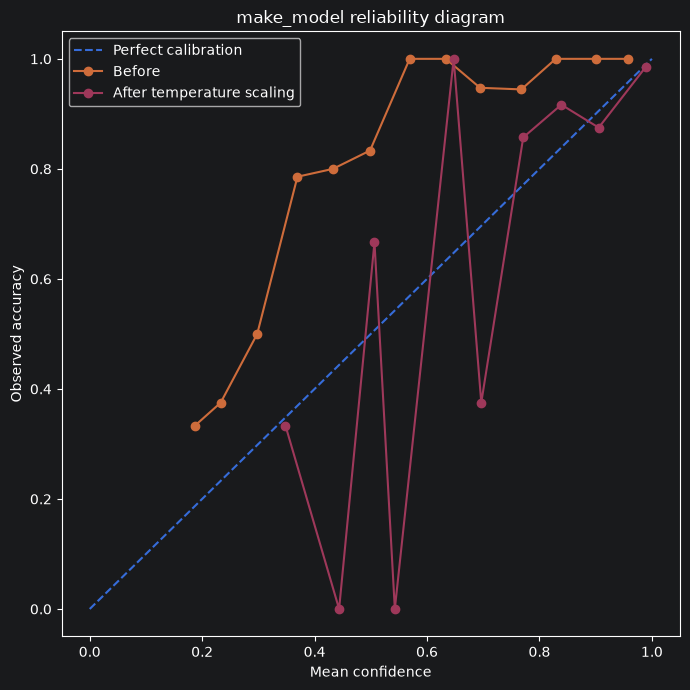


TASK: body_type
Architecture: convnext_tiny
Checkpoint: C:\Users\elesh\Academics\UTS\36127InnovationLab\Development\AutoVision_Model_Development\models\separate_attribute_benchmark\body_type\convnext_tiny_best.pt
Validation images: 120
Test images: 120
Classes: 12


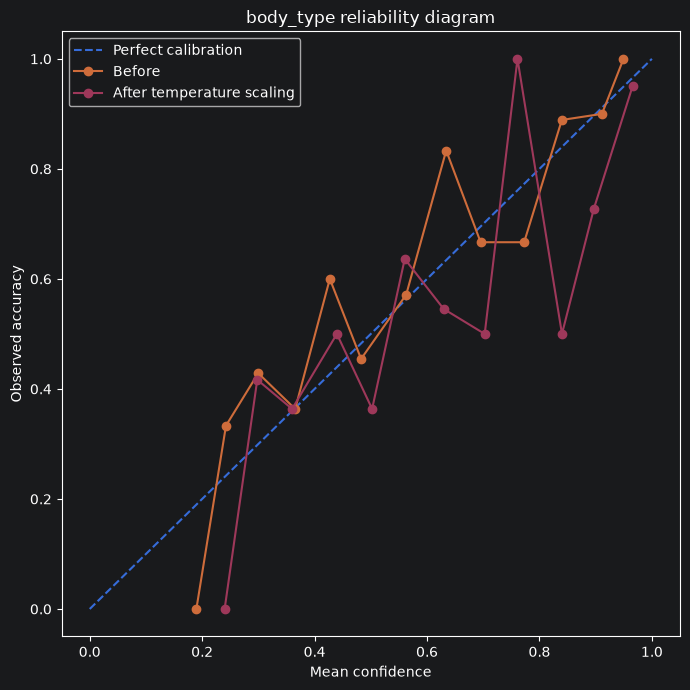


TASK: colour
Architecture: swin_t
Checkpoint: C:\Users\elesh\Academics\UTS\36127InnovationLab\Development\AutoVision_Model_Development\models\colour_architecture_benchmark\swin_t_colour_controlled_best.pt
Validation images: 100
Test images: 100
Classes: 10


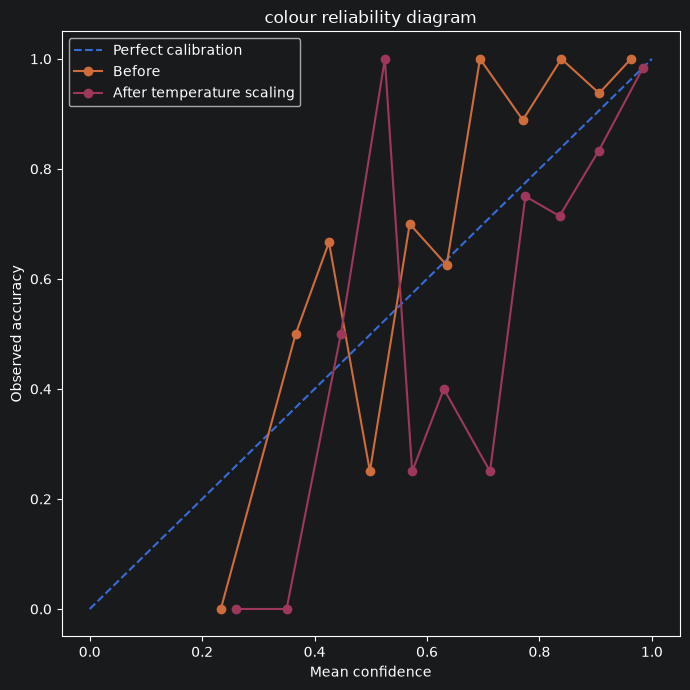

,task,architecture,checkpoint,num_classes,validation_images,test_images,test_accuracy_before,test_accuracy_after,temperature,ece_before,ece_after,nll_before,nll_after,brier_before,brier_after
0,make_model,resnet50,C:\Users\elesh\Academics\UTS\36127InnovationLa...,20,200,200,0.905000,0.905000,0.438928,0.230746,0.037522,0.555633,0.322254,0.218642,0.138734
1,body_type,convnext_tiny,C:\Users\elesh\Academics\UTS\36127InnovationLa...,12,120,120,0.583333,0.583333,0.766518,0.077564,0.108925,1.388378,1.428788,0.589996,0.592883
2,colour,swin_t,C:\Users\elesh\Academics\UTS\36127InnovationLa...,10,100,100,0.820000,0.820000,0.622006,0.104990,0.074827,0.494366,0.460391,0.240811,0.242443


Saved calibration outputs to: C:\Users\elesh\Academics\UTS\36127InnovationLab\Development\AutoVision_Model_Development\reports\confidence_calibration_final


In [35]:
summary_rows = []
temperature_map = {}
task_cache = {}

for task_name, cfg in TASKS.items():

    if not cfg["enabled"]:
        continue

    if (
        cfg["split_path"] is None
        or cfg["checkpoint_path"] is None
    ):
        print(
            f"SKIPPING {task_name}: "
            "split or checkpoint was not resolved."
        )
        continue

    print(
        "\n" + "=" * 70
    )
    print(
        "TASK:",
        task_name,
    )
    print(
        "=" * 70
    )

    split_info = load_task_split(
        task_name,
        cfg,
    )

    val_loader, test_loader = (
        make_loaders(
            split_info
        )
    )

    model, checkpoint_path = (
        load_task_model(
            task_name,
            cfg,
            split_info[
                "num_classes"
            ],
        )
    )

    print(
        "Architecture:",
        cfg["architecture"],
    )
    print(
        "Checkpoint:",
        checkpoint_path,
    )
    print(
        "Validation images:",
        len(split_info["val_df"]),
    )
    print(
        "Test images:",
        len(split_info["test_df"]),
    )
    print(
        "Classes:",
        split_info["num_classes"],
    )

    val_logits, val_labels = (
        collect_logits(
            model,
            val_loader,
        )
    )

    test_logits, test_labels = (
        collect_logits(
            model,
            test_loader,
        )
    )

    temperature = fit_temperature(
        val_logits,
        val_labels,
    )

    temperature_map[
        task_name
    ] = temperature

    probs_before = torch.softmax(
        test_logits,
        dim=1,
    )

    probs_after = torch.softmax(
        test_logits / temperature,
        dim=1,
    )

    ce = nn.CrossEntropyLoss()

    nll_before = float(
        ce(
            test_logits.float(),
            test_labels.long(),
        ).item()
    )

    nll_after = float(
        ce(
            test_logits.float()
            / temperature,
            test_labels.long(),
        ).item()
    )

    ece_before = (
        expected_calibration_error(
            probs_before,
            test_labels,
        )
    )

    ece_after = (
        expected_calibration_error(
            probs_after,
            test_labels,
        )
    )

    brier_before = (
        multiclass_brier(
            probs_before,
            test_labels,
        )
    )

    brier_after = (
        multiclass_brier(
            probs_after,
            test_labels,
        )
    )

    accuracy_before = float(
        probs_before.argmax(1)
        .eq(test_labels)
        .float()
        .mean()
    )

    accuracy_after = float(
        probs_after.argmax(1)
        .eq(test_labels)
        .float()
        .mean()
    )

    summary_rows.append({
        "task": task_name,
        "architecture": cfg["architecture"],
        "checkpoint": str(
            checkpoint_path
        ),
        "num_classes": split_info[
            "num_classes"
        ],
        "validation_images": len(
            split_info["val_df"]
        ),
        "test_images": len(
            split_info["test_df"]
        ),
        "test_accuracy_before": accuracy_before,
        "test_accuracy_after": accuracy_after,
        "temperature": temperature,
        "ece_before": ece_before,
        "ece_after": ece_after,
        "nll_before": nll_before,
        "nll_after": nll_after,
        "brier_before": brier_before,
        "brier_after": brier_after,
    })

    before_df = reliability_table(
        probs_before,
        test_labels,
    )

    after_df = reliability_table(
        probs_after,
        test_labels,
    )

    before_df.to_csv(
        REPORT_DIR
        / f"{task_name}_reliability_before.csv",
        index=False,
    )

    after_df.to_csv(
        REPORT_DIR
        / f"{task_name}_reliability_after.csv",
        index=False,
    )

    plt.figure(
        figsize=(7, 7)
    )

    plt.plot(
        [0, 1],
        [0, 1],
        linestyle="--",
        label="Perfect calibration",
    )

    plt.plot(
        before_df["mean_confidence"],
        before_df["accuracy"],
        marker="o",
        label="Before",
    )

    plt.plot(
        after_df["mean_confidence"],
        after_df["accuracy"],
        marker="o",
        label="After temperature scaling",
    )

    plt.xlabel(
        "Mean confidence"
    )

    plt.ylabel(
        "Observed accuracy"
    )

    plt.title(
        f"{task_name} reliability diagram"
    )

    plt.legend()
    plt.tight_layout()

    plt.savefig(
        REPORT_DIR
        / f"{task_name}_reliability_diagram.png",
        dpi=160,
    )

    plt.show()
    plt.close()

    task_cache[
        task_name
    ] = {
        "test_logits": test_logits,
        "test_labels": test_labels,
        "temperature": temperature,
    }

    del model

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


summary_df = pd.DataFrame(
    summary_rows
)

display(
    summary_df
)

summary_df.to_csv(
    REPORT_DIR
    / "calibration_comparison.csv",
    index=False,
)

with open(
    REPORT_DIR
    / "calibration_temperatures.json",
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        temperature_map,
        file,
        indent=2,
    )

print(
    "Saved calibration outputs to:",
    REPORT_DIR,
)

## 11. Confidence analysis

In [38]:
FINAL_TEMPERATURES = {
    "make_model": 0.438928,
    "body_type": 1.0,
    "colour": 0.622006,
}

THRESHOLDS = [
    0.50,
    0.60,
    0.70,
    0.80,
    0.90,
    0.95,
]

threshold_rows = []

for task_name, cached in (
    task_cache.items()
):

    test_logits = cached[
        "test_logits"
    ]

    test_labels = cached[
        "test_labels"
    ]

    temperature = FINAL_TEMPERATURES[
        task_name
    ]

    probabilities = torch.softmax(
        test_logits / temperature,
        dim=1,
    )

    confidence, prediction = (
        probabilities.max(dim=1)
    )

    correct = prediction.eq(
        test_labels
    )

    for threshold in THRESHOLDS:

        accepted = (
            confidence
            >= threshold
        )

        coverage = float(
            accepted.float().mean()
        )

        if accepted.any():
            accepted_accuracy = float(
                correct[
                    accepted
                ]
                .float()
                .mean()
            )
        else:
            accepted_accuracy = np.nan

        threshold_rows.append({
            "task": task_name,
            "threshold": threshold,
            "coverage": coverage,
            "accepted_accuracy": accepted_accuracy,
            "accepted_predictions": int(
                accepted.sum()
            ),
            "total_predictions": len(
                test_labels
            ),
        })


threshold_df = pd.DataFrame(
    threshold_rows
)

display(
    threshold_df
)

threshold_df.to_csv(
    REPORT_DIR
    / "confidence_threshold_analysis.csv",
    index=False,
)

,task,threshold,coverage,accepted_accuracy,accepted_predictions,total_predictions
0,make_model,0.50,0.955000,0.926702,191,200
1,make_model,0.60,0.930000,0.940860,186,200
2,make_model,0.70,0.900000,0.955556,180,200
3,make_model,0.80,0.850000,0.970588,170,200
4,make_model,0.90,0.755000,0.986755,151,200
5,make_model,0.95,0.670000,0.985075,134,200
6,body_type,0.50,0.475000,0.771930,57,120
7,body_type,0.60,0.341667,0.829268,41,120
8,body_type,0.70,0.275000,0.848485,33,120
9,body_type,0.80,0.191667,0.913043,23,120


## 12. Compact final summary

In [39]:
if len(summary_df) == 0:
    print(
        "No tasks were calibrated. "
        "Check the split and checkpoint paths in Section 2."
    )

else:
    final_view = summary_df[
        [
            "task",
            "architecture",
            "test_accuracy_before",
            "temperature",
            "ece_before",
            "ece_after",
            "nll_before",
            "nll_after",
            "brier_before",
            "brier_after",
        ]
    ].copy()

    display(
        final_view
    )

    print(
        "\nCalibration temperatures:"
    )

    for task_name, temperature in (
        temperature_map.items()
    ):
        print(
            f"{task_name}: {temperature:.4f}"
        )

,task,architecture,test_accuracy_before,temperature,ece_before,ece_after,nll_before,nll_after,brier_before,brier_after
0,make_model,resnet50,0.905000,0.438928,0.230746,0.037522,0.555633,0.322254,0.218642,0.138734
1,body_type,convnext_tiny,0.583333,0.766518,0.077564,0.108925,1.388378,1.428788,0.589996,0.592883
2,colour,swin_t,0.820000,0.622006,0.104990,0.074827,0.494366,0.460391,0.240811,0.242443



Calibration temperatures:
make_model: 0.4389
body_type: 0.7665
colour: 0.6220
